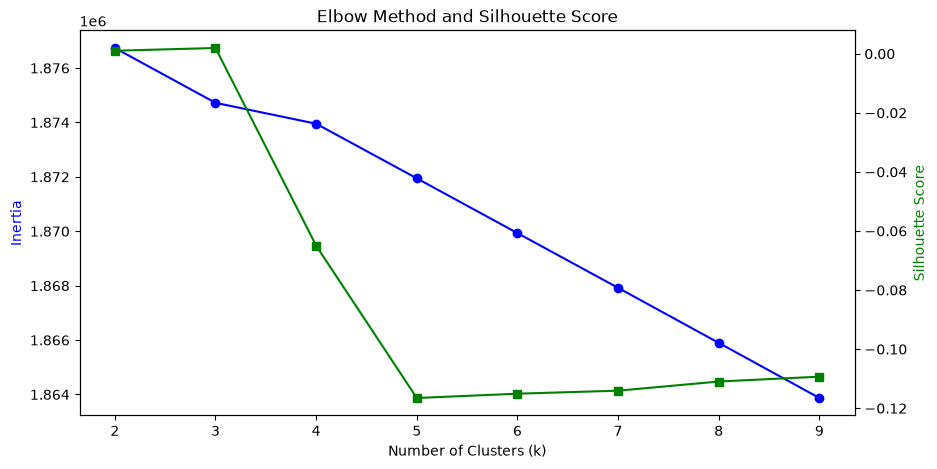

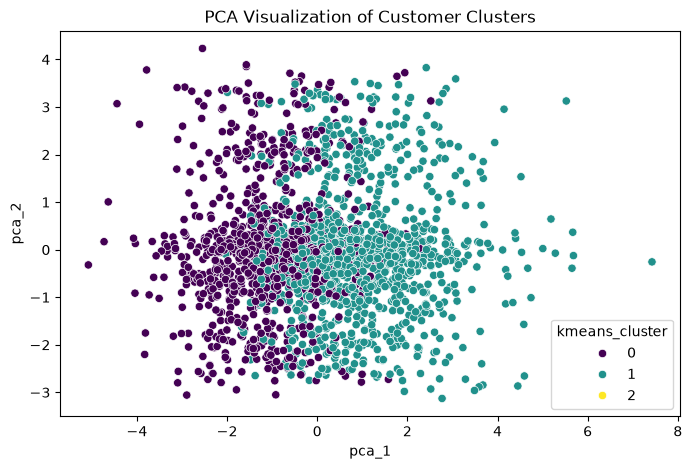

                total_orders  total_spending  avg_order_value
kmeans_cluster                                               
0                   5.888136      135.724780        23.380120
1                   8.778077      242.725139        28.247442
2                   9.500000      225.700000        23.533944


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Part 1: Feature Engineering
# Load datasets (Adjust paths if necessary)
customers = pd.read_csv('../data/customers.csv')
orders = pd.read_csv('../data/orders.csv')

# Aggregate order data per customer
customer_metrics = orders.groupby('customer_id').agg(
    total_orders=('order_id', 'count'),
    total_spending=('order_amount', 'sum'),
    avg_order_value=('order_amount', 'mean')
).reset_index()

# Merge with customer demographics and drop the identifier for modeling
df = pd.merge(customers, customer_metrics, on='customer_id', how='inner')
customer_ids = df['customer_id'] # Save for later
X = df.drop(columns=['customer_id'])

# Apply one-hot encoding to convert categorical strings to numeric values
X = pd.get_dummies(X, drop_first=True)

# Part 2: Feature Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Part 3: K-Means Clustering (Elbow & Silhouette)
inertia = []
silhouette_scores = []
K_range = range(2, 10)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, kmeans.labels_))

# Plot Elbow and Silhouette
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(K_range, inertia, marker='o', color='b', label='Inertia (Elbow)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia', color='b')

ax2 = ax1.twinx()
ax2.plot(K_range, silhouette_scores, marker='s', color='g', label='Silhouette Score')
ax2.set_ylabel('Silhouette Score', color='g')
plt.title('Elbow Method and Silhouette Score')
plt.show()

# Apply Final K-Means (Assuming optimal k=3 based on above plots)
kmeans_final = KMeans(n_clusters=3, random_state=42)
df['kmeans_cluster'] = kmeans_final.fit_predict(X_scaled)

# Part 4: DBSCAN
dbscan = DBSCAN(eps=0.5, min_samples=5)
df['dbscan_cluster'] = dbscan.fit_predict(X_scaled)

# Part 5: PCA & Visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df['pca_1'] = X_pca[:, 0]
df['pca_2'] = X_pca[:, 1]

plt.figure(figsize=(8, 5))
sns.scatterplot(x='pca_1', y='pca_2', hue='kmeans_cluster', palette='viridis', data=df)
plt.title('PCA Visualization of Customer Clusters')
plt.show()

# Part 6: Business Profiling
cluster_profiles = df.groupby('kmeans_cluster')[['total_orders', 'total_spending', 'avg_order_value']].mean()
print(cluster_profiles)

# Example mapping based on cluster profiles
cluster_names = {
    0: 'Occasional Budget Customers',
    1: 'Premium Frequent Diners',
    2: 'Late-Night High-Value Customers'
}
df['business_segment'] = df['kmeans_cluster'].map(cluster_names)